# Klasifikasi Bunga: CNN dari Nol vs Transfer Learning (MobileNetV2)

**Tugas Individu Deep Learning**

- Nama: *DIANI ANNISAH*
- NIM: *H071241043*
- Dataset: TF Flowers, 5 kelas (daisy, dandelion, roses, sunflowers, tulips), 3.670 gambar, split 80% train / 20% validasi
- Model: (1) CNN custom, (2) Transfer Learning MobileNetV2

**Tujuan:** membandingkan CNN yang dilatih dari nol dengan transfer learning pada dataset gambar yang sama, dari sisi akurasi, waktu training, dan overfitting.

## 1. Import Library

In [1]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download dan Load Dataset

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file("flower_photos.tar", origin=URL, extract=True)

# Cari folder yang langsung berisi subfolder kelas (daisy, dandelion, dst.)
data_dir = None
for root, dirs, _ in os.walk(os.path.dirname(archive)):
    if {"daisy", "roses", "tulips"}.issubset(set(dirs)):
        data_dir = root
        break
assert data_dir is not None, "Folder kelas bunga tidak ditemukan"
print("Folder data:", data_dir, "| isi:", sorted(os.listdir(data_dir)))

IMG_SIZE = (160, 160)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH)
val_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
assert NUM_CLASSES == 5, f"Harusnya 5 kelas, terbaca {NUM_CLASSES}: {class_names}"
print("Kelas:", class_names)

# Materialisasi data validasi sekali saja agar urutannya tetap
# (penting supaya label asli cocok dengan prediksi saat evaluasi).
# PENTING: gambar dan label diambil dalam SATU iterasi, karena val_raw diacak
# ulang setiap kali dibaca (kalau dibaca dua kali, pasangan gambar-label rusak).
xs, ys = [], []
for x, y in val_raw:
    xs.append(x.numpy()); ys.append(y.numpy())
val_images = np.concatenate(xs).astype("float32")
y_true = np.concatenate(ys).astype(int)
val_ds = tf.data.Dataset.from_tensor_slices((val_images, y_true)).batch(BATCH)
print("Train batch:", len(train_ds), "| Val gambar:", len(y_true))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Folder data: /root/.keras/datasets/flower_photos_extracted/flower_photos | isi: ['LICENSE.txt', 'daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Kelas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Train batch: 92 | Val gambar: 734


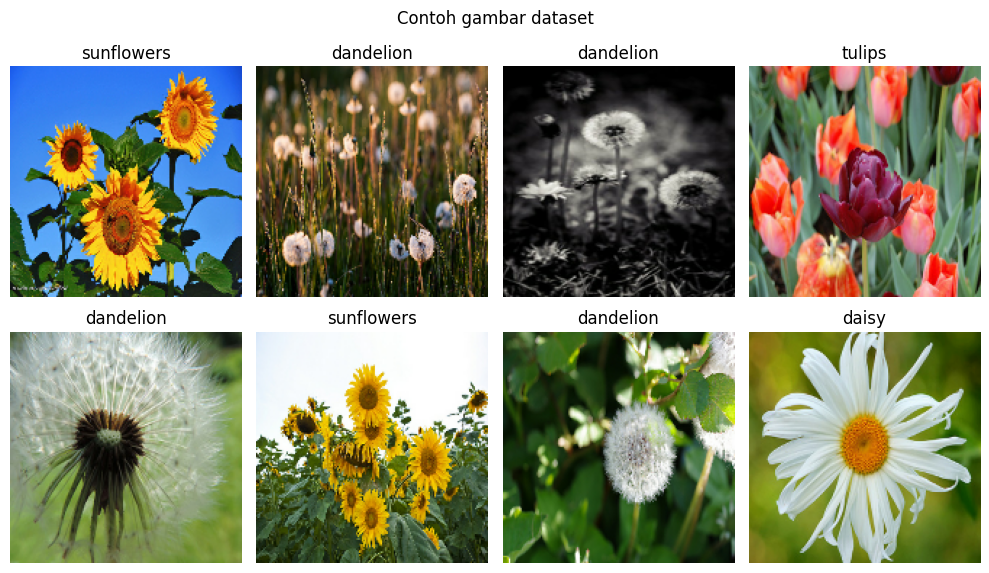

In [3]:
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.suptitle("Contoh gambar dataset")
plt.tight_layout()
plt.show()

## 3. Model 1: CNN Custom (dari nol)

Arsitektur: data augmentation, rescaling, 3 blok `Conv2D + MaxPooling`, `Flatten`, `Dropout`, lalu `Dense` softmax (5 kelas).

In [4]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    x = layers.Rescaling(1./255)(x)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_custom")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "cnn_custom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

t0 = time.time()
hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early])
time_cnn = time.time() - t0
print(f"Waktu training CNN: {time_cnn:.1f} detik")

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - accuracy: 0.3968 - loss: 1.3636 - val_accuracy: 0.4809 - val_loss: 1.1376
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5354 - loss: 1.0981 - val_accuracy: 0.5858 - val_loss: 1.0286
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6114 - loss: 0.9687 - val_accuracy: 0.6240 - val_loss: 1.0095
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6448 - loss: 0.9005 - val_accuracy: 0.6403 - val_loss: 0.9908
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6703 - loss: 0.8363 - val_accuracy: 0.6431 - val_loss: 0.9462
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.6928 - loss: 0.7876 - val_accuracy: 0.6880 - val_loss: 0.8555
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6989 - loss: 0.7692 - val_accuracy: 0.6839 - val_loss: 0.8932
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.7112 - loss: 0.7283 - val_accuracy: 0.6866 - 

## 4. Model 2: Transfer Learning (MobileNetV2)

Tahap 1 (*feature extraction*): base model MobileNetV2 pretrained ImageNet dibekukan, hanya head baru yang dilatih.
Tahap 2 (*fine-tuning*): 30 layer terakhir base model dibuka dan dilatih dengan learning rate kecil.

In [6]:
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False

def build_tl():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    x = layers.Rescaling(1./127.5, offset=-1)(x)   # skala [-1, 1] sesuai MobileNetV2
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_tl")

tl = build_tl()
tl.compile(optimizer=keras.optimizers.Adam(1e-3),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
tl.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Tahap 1: feature extraction
t0 = time.time()
hist_tl1 = tl.fit(train_ds, validation_data=val_ds, epochs=8)
time_tl1 = time.time() - t0
print(f"Waktu tahap 1: {time_tl1:.1f} detik")

Epoch 1/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.6526 - loss: 0.9292 - val_accuracy: 0.8297 - val_loss: 0.4900
Epoch 2/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8178 - loss: 0.4975 - val_accuracy: 0.8474 - val_loss: 0.4297
Epoch 3/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8501 - loss: 0.4270 - val_accuracy: 0.8556 - val_loss: 0.4012
Epoch 4/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.8604 - loss: 0.3760 - val_accuracy: 0.8569 - val_loss: 0.3870
Epoch 5/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8716 - loss: 0.3456 - val_accuracy: 0.8610 - val_loss: 0.3745
Epoch 6/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8859 - loss: 0.3200 - val_accuracy: 0.8610 - val_loss: 0.3659
Epoch 7/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8948 - loss: 0.2925 - val_accuracy: 0.8624 - val_loss: 0.3732
Epoch 8/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.8937 - loss: 0.2932 - val_accuracy: 0.8624 - val_loss

In [8]:
# Tahap 2: fine-tuning 30 layer terakhir
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

tl.compile(optimizer=keras.optimizers.Adam(1e-5),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_tl2 = tl.fit(train_ds, validation_data=val_ds, epochs=5)
time_tl2 = time.time() - t0
time_tl = time_tl1 + time_tl2
print(f"Waktu fine-tuning: {time_tl2:.1f} detik | total TL: {time_tl:.1f} detik")

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - accuracy: 0.8225 - loss: 0.4910 - val_accuracy: 0.8733 - val_loss: 0.3673
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.8535 - loss: 0.3899 - val_accuracy: 0.8719 - val_loss: 0.3603
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.8740 - loss: 0.3377 - val_accuracy: 0.8801 - val_loss: 0.3481
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.8873 - loss: 0.3094 - val_accuracy: 0.8883 - val_loss: 0.3408
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.8931 - loss: 0.2983 - val_accuracy: 0.8869 - val_loss: 0.3394
Waktu fine-tuning: 34.0 detik | total TL: 69.2 detik


## 5. Kurva Training

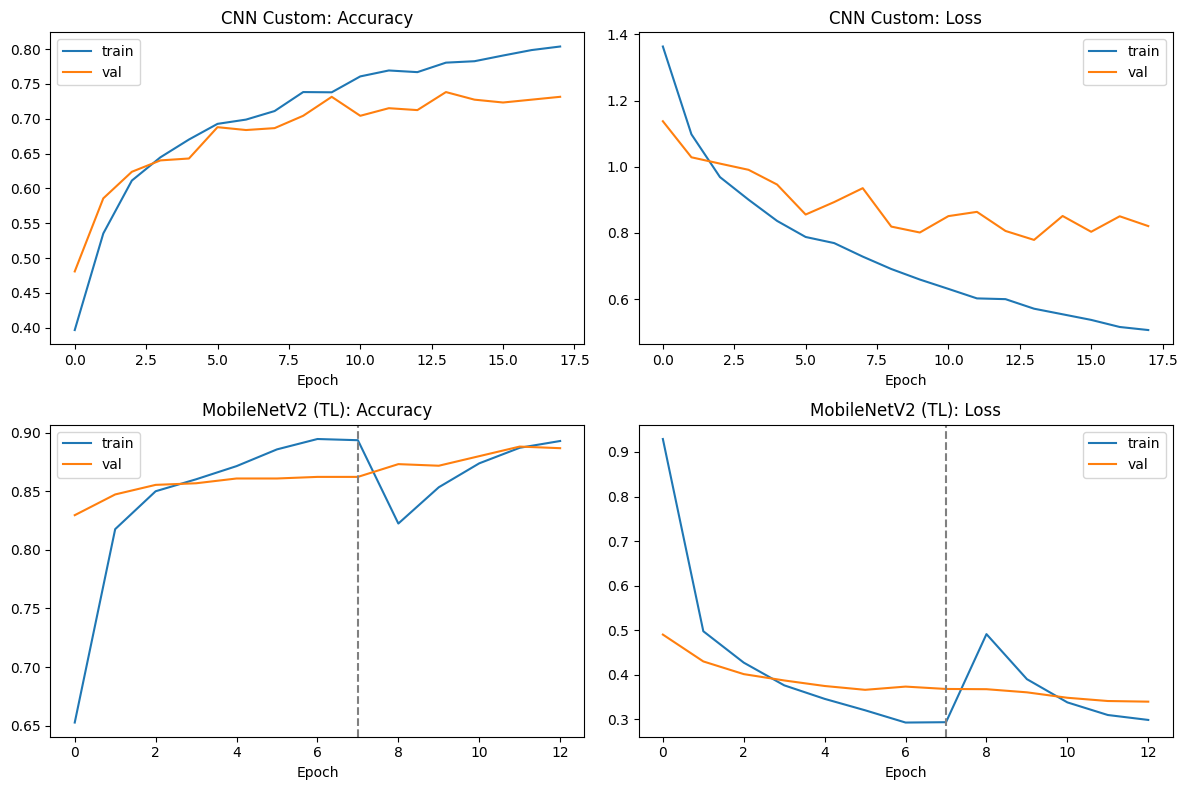

In [9]:
def merge(*hists):
    out = {}
    for k in ("accuracy", "val_accuracy", "loss", "val_loss"):
        out[k] = sum([h.history[k] for h in hists], [])
    return out

h_cnn = merge(hist_cnn)
h_tl = merge(hist_tl1, hist_tl2)
ft_start = len(hist_tl1.history["accuracy"])

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, h) in enumerate([("CNN Custom", h_cnn), ("MobileNetV2 (TL)", h_tl)]):
    ax[row, 0].plot(h["accuracy"], label="train"); ax[row, 0].plot(h["val_accuracy"], label="val")
    ax[row, 0].set_title(f"{name}: Accuracy"); ax[row, 0].legend()
    ax[row, 1].plot(h["loss"], label="train"); ax[row, 1].plot(h["val_loss"], label="val")
    ax[row, 1].set_title(f"{name}: Loss"); ax[row, 1].legend()
    if row == 1:
        for a in ax[row]: a.axvline(ft_start - 1, color="gray", ls="--", label="mulai fine-tuning")
for a in ax.flat: a.set_xlabel("Epoch")
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/training_curves.png", dpi=150)
plt.show()

## 6. Evaluasi: Confusion Matrix dan Classification Report

=== CNN Custom ===
              precision    recall  f1-score   support

       daisy     0.6350    0.8131    0.7131       107
   dandelion     0.8133    0.7068    0.7563       191
       roses     0.6667    0.6891    0.6777       119
  sunflowers     0.7468    0.8519    0.7958       135
      tulips     0.7987    0.6758    0.7321       182

    accuracy                         0.7384       734
   macro avg     0.7321    0.7473    0.7350       734
weighted avg     0.7477    0.7384    0.7385       734

=== MobileNetV2 (Transfer Learning) ===
              precision    recall  f1-score   support

       daisy     0.8333    0.9346    0.8811       107
   dandelion     0.9402    0.9058    0.9227       191
       roses     0.8430    0.8571    0.8500       119
  sunflowers     0.8690    0.9333    0.9000       135
      tulips     0.9146    0.8242    0.8671       182

    accuracy                         0.8869       734
   macro avg     0.8800    0.8910    0.8842       734
weighted avg     0

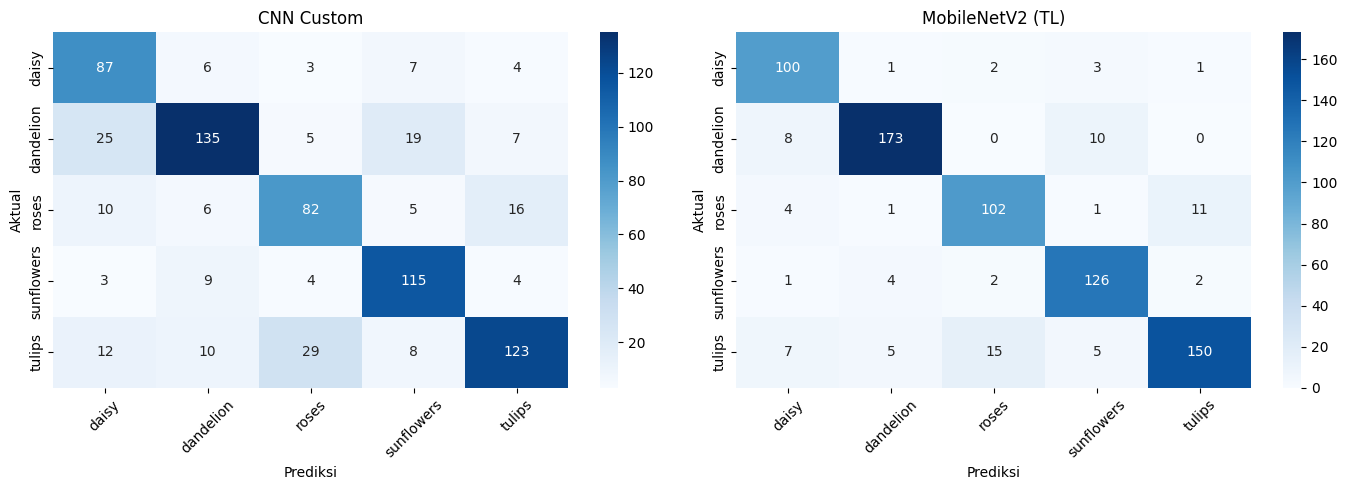

In [10]:
def evaluate(model, name):
    probs = model.predict(val_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    return y_pred, cm

pred_cnn, cm_cnn = evaluate(cnn, "CNN Custom")
pred_tl, cm_tl = evaluate(tl, "MobileNetV2 (Transfer Learning)")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, cm, t in zip(ax, [cm_cnn, cm_tl], ["CNN Custom", "MobileNetV2 (TL)"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, ax=a)
    a.tick_params(axis="x", rotation=45)
    a.set_title(t); a.set_xlabel("Prediksi"); a.set_ylabel("Aktual")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

## 7. Contoh Prediksi Salah (Error Analysis)

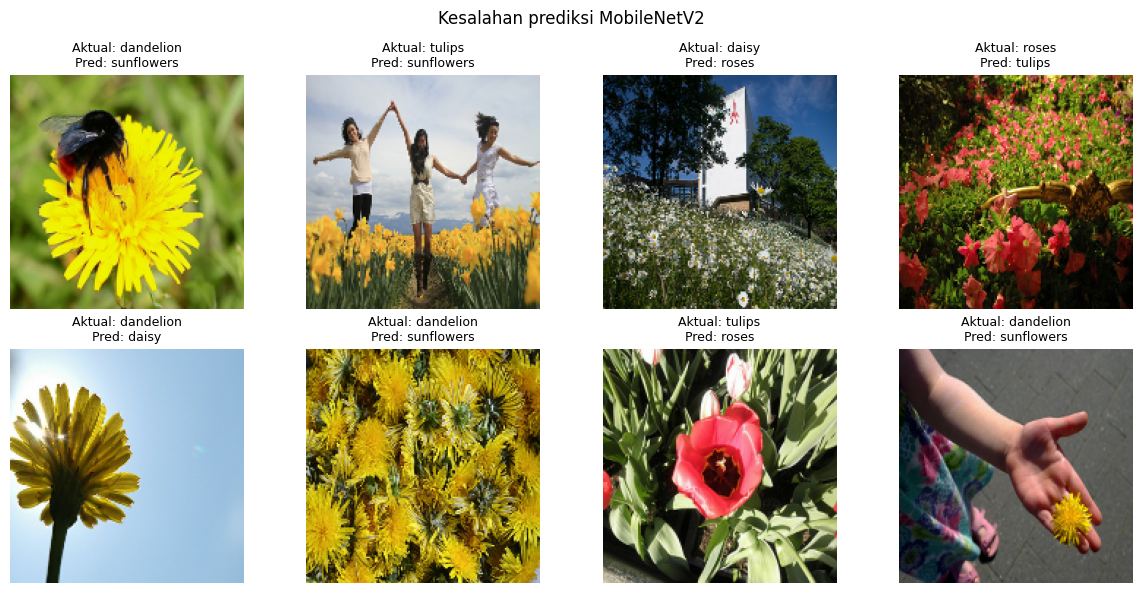

In [11]:
images_all = val_images.astype("uint8")
wrong = np.where(pred_tl != y_true)[0][:8]

plt.figure(figsize=(12, 6))
for i, idx in enumerate(wrong):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images_all[idx])
    plt.title(f"Aktual: {class_names[y_true[idx]]}\nPred: {class_names[pred_tl[idx]]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Kesalahan prediksi MobileNetV2")
plt.tight_layout()
plt.savefig("images/wrong_predictions.png", dpi=150)
plt.show()

## 8. Perbandingan Model

In [12]:
import pandas as pd

def summary_row(name, model, h, t):
    return {
        "Model": name,
        "Parameter": f"{model.count_params():,}",
        "Train Acc": round(h["accuracy"][-1], 4),
        "Val Acc": round(h["val_accuracy"][-1], 4),
        "Gap (Train-Val)": round(h["accuracy"][-1] - h["val_accuracy"][-1], 4),
        "Val Loss": round(h["val_loss"][-1], 4),
        "Waktu Training (s)": round(t, 1),
    }

df = pd.DataFrame([
    summary_row("CNN Custom", cnn, h_cnn, time_cnn),
    summary_row("MobileNetV2 (TL)", tl, h_tl, time_tl),
])
df

,Model,Parameter,Train Acc,Val Acc,Gap (Train-Val),Val Loss,Waktu Training (s)
0,CNN Custom,"6,647,621",0.8038,0.7316,0.0722,0.8206,68.4
1,MobileNetV2 (TL),"2,264,389",0.8931,0.8869,0.0061,0.3394,69.2
